# Exercise 1: Random Forest Classification – Fruit Basket

**Subject:** Machine Learning Lab

**Topic:** Random Forests

## Aim
To implement a Random Forest Classifier to classify fruits based on their features and evaluate its performance.

Fruit Basket Dataset:


,Weight,Sweetness,Fruit
0,150,7,Apple
1,170,8,Apple
2,140,6,Apple
3,160,7,Apple
4,180,9,Apple
5,155,8,Apple
6,145,6,Apple
7,175,9,Apple
8,120,4,Orange
9,130,5,Orange


Training samples: 18
Testing samples: 6
Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

       Apple       1.00      1.00      1.00         2
       Mango       1.00      1.00      1.00         2
      Orange       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



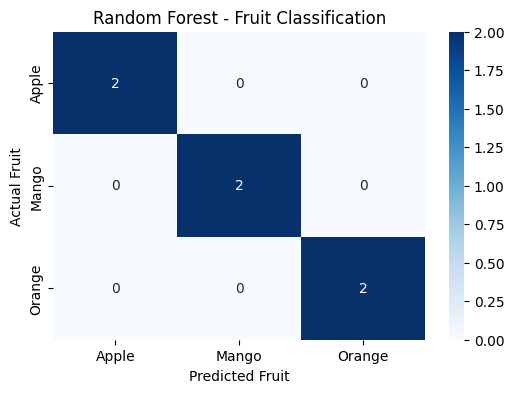

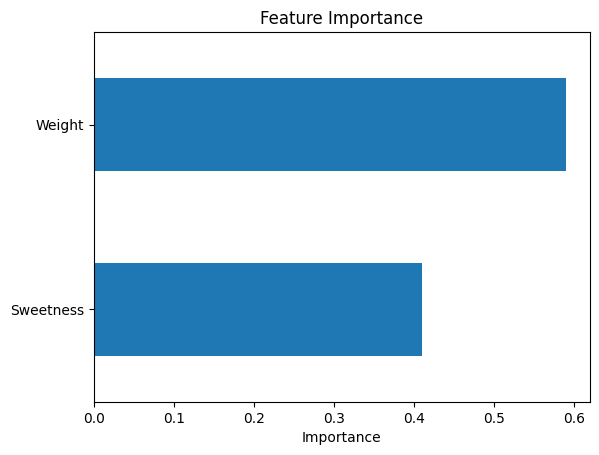

New fruit prediction: Apple


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create a fruit basket dataset
data = {
    "Weight": [
        150, 170, 140, 160, 180, 155, 145, 175,
        120, 130, 110, 125, 135, 115, 128, 118,
        180, 200, 190, 210, 195, 185, 205, 198
    ],
    "Sweetness": [
        7, 8, 6, 7, 9, 8, 6, 9,
        4, 5, 3, 4, 5, 3, 4, 3,
        6, 7, 6, 8, 7, 6, 8, 7
    ],
    "Fruit": [
        "Apple", "Apple", "Apple", "Apple",
        "Apple", "Apple", "Apple", "Apple",
        "Orange", "Orange", "Orange", "Orange",
        "Orange", "Orange", "Orange", "Orange",
        "Mango", "Mango", "Mango", "Mango",
        "Mango", "Mango", "Mango", "Mango"
    ]
}

df = pd.DataFrame(data)

print("Fruit Basket Dataset:")
display(df.head(10))

X = df[["Weight", "Sweetness"]]
y = df["Fruit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)
plt.xlabel("Predicted Fruit")
plt.ylabel("Actual Fruit")
plt.title("Random Forest - Fruit Classification")
plt.show()

importance = pd.Series(
    model.feature_importances_, index=X.columns
).sort_values()

importance.plot(kind="barh")
plt.xlabel("Importance")
plt.title("Feature Importance")
plt.show()

new_fruit = pd.DataFrame({"Weight": [165], "Sweetness": [8]})
print("New fruit prediction:", model.predict(new_fruit)[0])

## Result

The Random Forest Classifier was successfully implemented to classify apples, mangoes, and oranges using weight and sweetness. The model achieved 100% test accuracy on the six test samples. The classification report and confusion matrix confirmed that all test samples were classified correctly. Feature importance was visualized to compare the contribution of the input features.

## Conclusion

The experiment demonstrated that a Random Forest Classifier can classify fruits using multiple decision trees. The model successfully predicted fruit categories based on weight and sweetness. Feature importance analysis showed that weight had a greater contribution than sweetness in this particular dataset.